# Лабораторная работа №3

## Задания

![Задания](./tasks.png "Задания")

## Библиотеки

В лекции ошибка, тестов PhillipsPerron и DFGLS нету в statsmodels. Для них нужно импортировать библиотеку arch

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from arch.unitroot import PhillipsPerron, DFGLS
from scipy.stats import boxcox
from pmdarima.arima import ndiffs, nsdiffs

## Реализация

### Загрузка данных

In [2]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"])
df.head()

,timestamp,value
0,2026-11-21 00:00:00,77.606167
1,2026-11-21 01:00:00,77.809007
2,2026-11-21 02:00:00,66.221119
3,2026-11-21 03:00:00,76.602630
4,2026-11-21 04:00:00,44.947280


### Необходимые преобразования

In [3]:
def adjust_df(df_orig):
    # Сортировка и проверка дубликатов
    df = df_orig.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")

    # Установка временного индекса и проверка частоты
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
    df = df.reindex(full_idx)
    df.index.name = "timestamp"

    return df

In [4]:
df = adjust_df(df)
df.head()

,value
timestamp,
2026-11-21 00:00:00,77.606167
2026-11-21 01:00:00,77.809007
2026-11-21 02:00:00,66.221119
2026-11-21 03:00:00,76.602630
2026-11-21 04:00:00,44.947280


### График ряда

In [5]:
def plot_series(df):
    plt.figure(figsize=(15, 5))
    plt.plot(df.index, df["value"], label="y")
    plt.show()

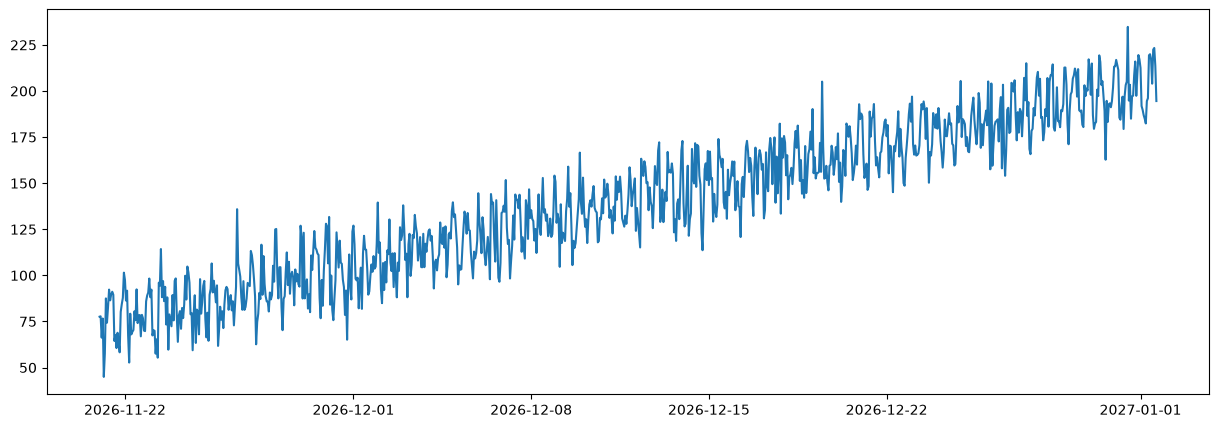

In [6]:
plot_series(df)

### Автокорреляционная функция

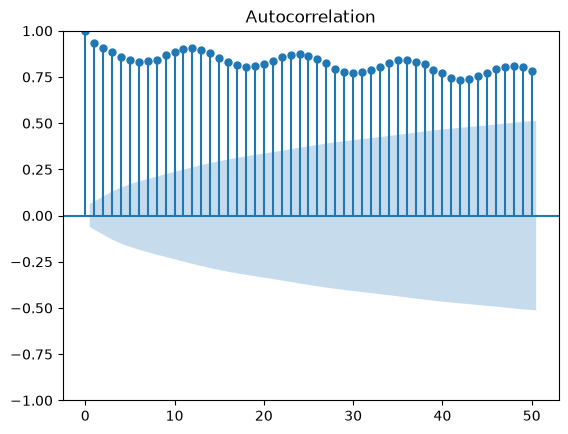

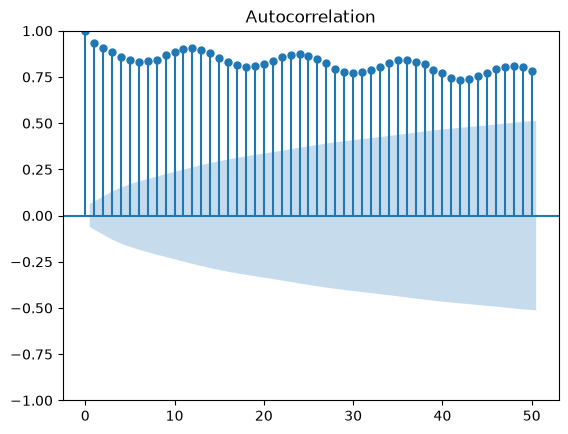

In [7]:
plot_acf(df, lags=50)

### Частная автокорреляционная функция

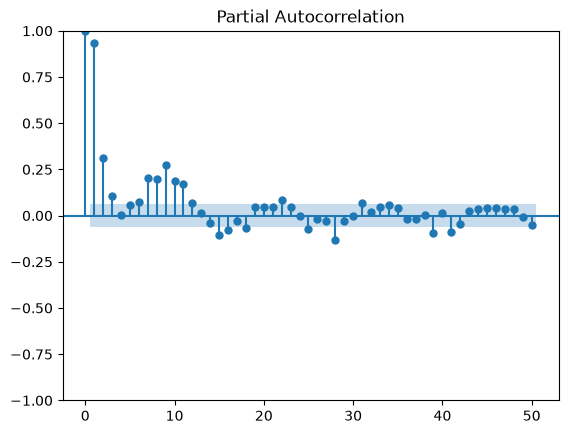

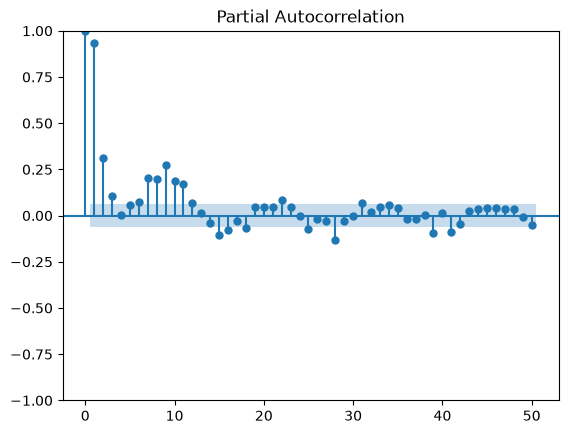

In [8]:
plot_pacf(df, lags=50)

### Предварительные выводы

* По ACF наблюдается медленное затухание - ряд **нестационарен**
* По PACF затухание быстрее, т.к. убрали более короткие лаги - ряд имеет **линейный тренд**
* По PACF видно **постоянную сезонность**
* По графику экспоненциального роста не наблюдается - модель **аддитивная**

### ADF

* $H_0$ - ряд содержит единичный корень, т.е. нестационарен
* $H_1$ - ряд стационарен

Если p-value малое, то отвергаем $H_0$

In [9]:
print(adfuller(df, result_object=True))

ADFullerResult
ADF Statistic: -0.20531
P-value: 0.93789
Used Lag: 22
Nobs: 977
Critical Values: {'1%': np.float64(-3.43706091543889), '5%': np.float64(-2.8645028204932483), '10%': np.float64(-2.568347558984588)}



p-value большое, значение статистики заметно больше критических значений, значит нет оснований отвергать $H_0$

### PP

* $H_0$ - ряд содержит единичный корень, т.е. нестационарен
* $H_1$ - ряд стационарен

Если p-value малое, то отвергаем $H_0$

In [10]:
print(PhillipsPerron(df))

     Phillips-Perron Test (Z-tau)    
Test Statistic                 -5.062
P-value                         0.000
Lags                               22
-------------------------------------

Trend: Constant
Critical Values: -3.44 (1%), -2.86 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


Здесь p-value очень маленькое и значения статистики сильно меньше критических значений, значит $H_0$ отвергается

### KPSS

* $H_0$ - ряд стационарен
* $H_1$ - ряд содержит единичный корень, т.е. нестационарен

Если p-value малое, то отвергаем $H_0$

In [11]:
print(kpss(df["value"], result_object=True))

KPSSResult
KPSS Statistic: 5.08227
P-value: 0.01000
Lags: 19
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}



/tmp/ipykernel_67061/362323023.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  print(kpss(df["value"], result_object=True))


p-value очень маленькое, значение статистики сильно больше критических значений, значит $H_0$ отвергается

### DFGLS

* $H_0$ - ряд содержит единичный корень, т.е. нестационарен
* $H_1$ - ряд стационарен

Если p-value малое, то отвергаем $H_0$

In [12]:
print(DFGLS(df))

      Dickey-Fuller GLS Results      
Test Statistic                  3.804
P-value                         1.000
Lags                               22
-------------------------------------

Trend: Constant
Critical Values: -2.59 (1%), -1.97 (5%), -1.64 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


p-value равно 1, статистика больше критических значений, следовательно нет оснований отвергать $H_0$

### Выводы по тестам

* ADF: p-value = 0.93789 => ряд нестационарен
* PP: p-value = 0 => ряд стационарен
* KPSS: p-value < 0.01 => ряд нестационарен
* DFGLS: p-value = 1 => ряд нестационарен

Смотря на ACF и на результаты тестов, можно сказать, что ряд нестационарен (я не до конца понимаю, почему у PP получилось такое p-value)

### Первые разности

Построим график и проведём тесты на df.diff(), т.е. вычтем из последующего элемента предыдущий

In [13]:
df_diff = df.diff(1).dropna()  # первый элемент будет NaN, т.к. нечего вычитать из него

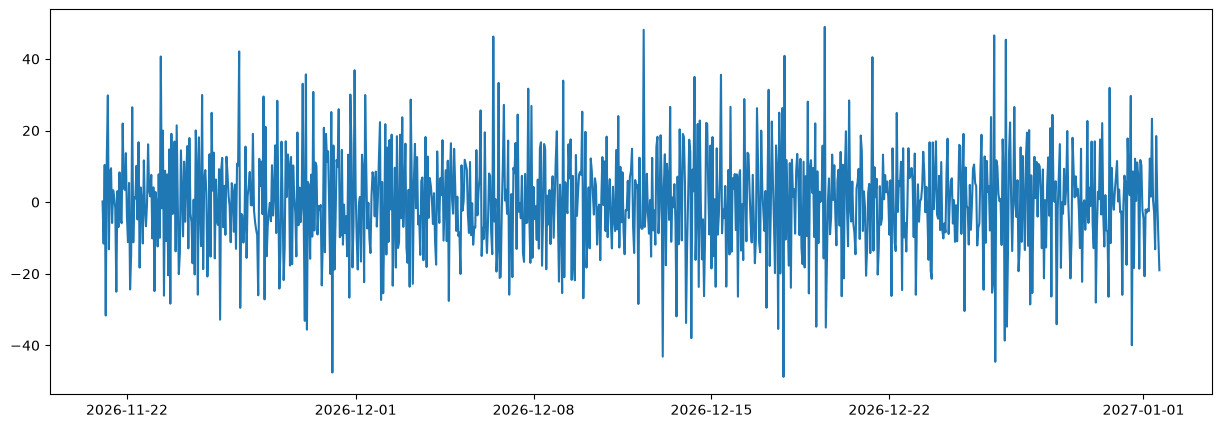

In [14]:
plot_series(df_diff)

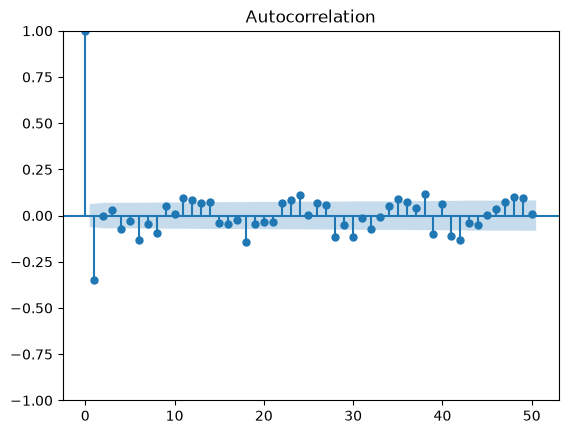

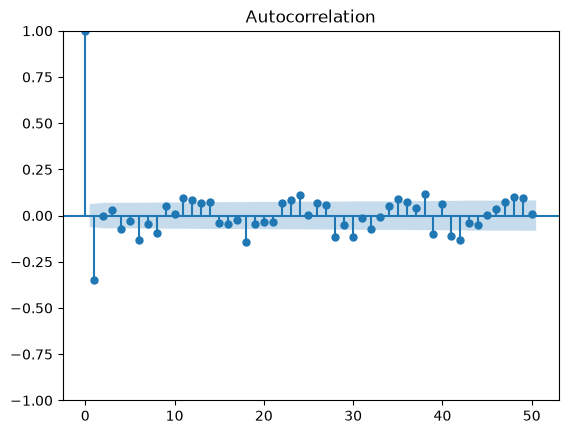

In [15]:
plot_acf(df_diff, lags=50)

In [16]:
print(adfuller(df_diff, result_object=True))

ADFullerResult
ADF Statistic: -13.18367
P-value: 0.00000
Used Lag: 22
Nobs: 976
Critical Values: {'1%': np.float64(-3.4370678095881804), '5%': np.float64(-2.8645058608075264), '10%': np.float64(-2.568349178354273)}



In [17]:
print(PhillipsPerron(df_diff))

     Phillips-Perron Test (Z-tau)    
Test Statistic               -127.733
P-value                         0.000
Lags                               22
-------------------------------------

Trend: Constant
Critical Values: -3.44 (1%), -2.86 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


In [18]:
print(kpss(df_diff["value"], result_object=True))

KPSSResult
KPSS Statistic: 0.03361
P-value: 0.10000
Lags: 35
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}



/tmp/ipykernel_67061/1934428695.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  print(kpss(df_diff["value"], result_object=True))


In [19]:
print(DFGLS(df_diff))

      Dickey-Fuller GLS Results      
Test Statistic                -12.896
P-value                         0.000
Lags                               22
-------------------------------------

Trend: Constant
Critical Values: -2.59 (1%), -1.97 (5%), -1.64 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


### Выводы по первым разностям

* ACF стала быстро затухать, но наблюдается сезонность => тренд удалён
* ADF p-value = 0 => ряд стационарен
* PP p-value = 0 => ряд стационарен
* KPSS p-value > 0.1 => ряд стационарен
* DFGLS p-value = 0 => ряд стационарен

После первых разностей тренд удалился (т.к. он был линейным) по тестам ряд стал стационарным, однако на ACF ещё осталась сезонность. Нужно сделать разницу и по ней

### Сезонная разность

На первые разности добавим ещё разность, но уже с периодом, равным сезонности (12 в нашем случае)

In [20]:
df_seas_diff = df_diff.diff(12).dropna()

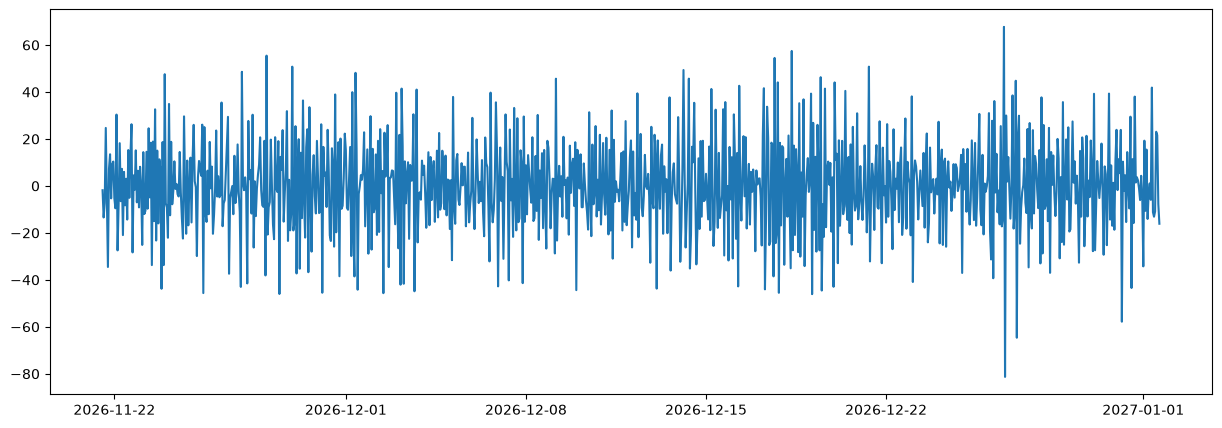

In [21]:
plot_series(df_seas_diff)

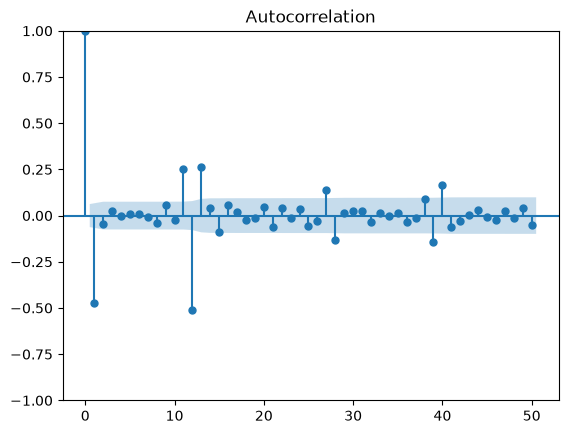

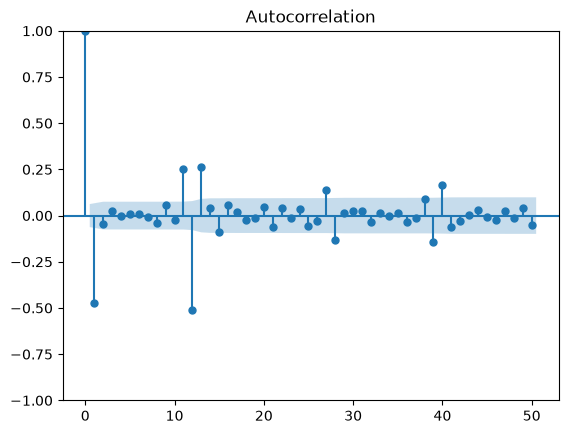

In [22]:
plot_acf(df_seas_diff, lags=50)

In [23]:
print(adfuller(df_seas_diff, result_object=True))

ADFullerResult
ADF Statistic: -9.82967
P-value: 0.00000
Used Lag: 22
Nobs: 964
Critical Values: {'1%': np.float64(-3.437151658028634), '5%': np.float64(-2.8645428373470563), '10%': np.float64(-2.5683688733406793)}



In [24]:
print(PhillipsPerron(df_seas_diff))

     Phillips-Perron Test (Z-tau)    
Test Statistic               -148.150
P-value                         0.000
Lags                               22
-------------------------------------

Trend: Constant
Critical Values: -3.44 (1%), -2.86 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


In [25]:
print(kpss(df_seas_diff["value"], result_object=True))

KPSSResult
KPSS Statistic: 0.44629
P-value: 0.05720
Lags: 841
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}



In [26]:
print(DFGLS(df_seas_diff))

      Dickey-Fuller GLS Results      
Test Statistic                 -1.833
P-value                         0.065
Lags                               22
-------------------------------------

Trend: Constant
Critical Values: -2.59 (1%), -1.97 (5%), -1.64 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


### Выводы по сезонной разности

* ACF быстро затухает, сезонности не наблюдается => ряд стационарен, т.к. нету тренда и сезонности
* ADF p-value = 0 => ряд стационарен
* PP p-value = 0 => ряд стационарен
* KPSS p-value = 0.05720 => ряд стационарен с уровнем доверия 0.05
* DFGLS p-value = 0.065 => ряд стационарен с уровнем доверия 0.1

Повторная разность убрала сезонность, однако оценки тестов ухудшились из-за добавления лишней дисперсии и местами отрицательной корреляции

### BOXCOX

Обобщение логарифма:

* $y = \frac{x^{\lambda}-1}{\lambda}$ при $\lambda \ne 0$
* $y = log(x)$ при $\lambda = 0$

In [27]:
df_boxcox = df.copy()
df_boxcox["value"] = boxcox(df["value"], lmbda=0)

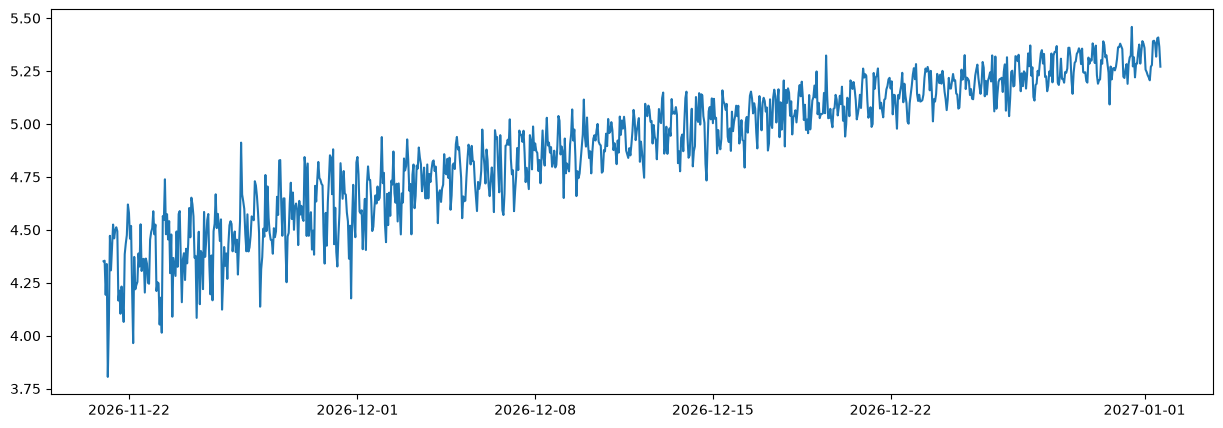

In [28]:
plot_series(df_boxcox)

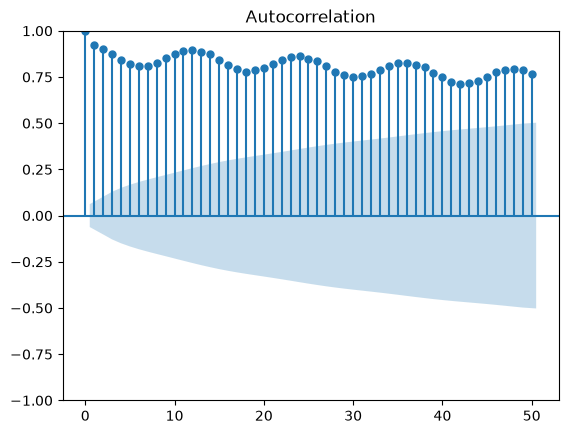

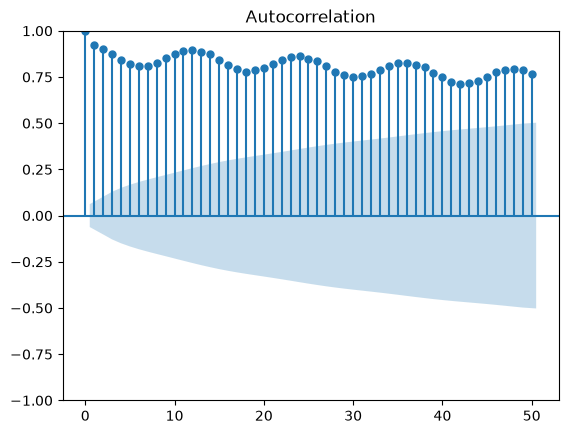

In [29]:
plot_acf(df_boxcox, lags=50)

In [30]:
print(adfuller(df_boxcox, result_object=True))

ADFullerResult
ADF Statistic: -1.72488
P-value: 0.41834
Used Lag: 22
Nobs: 977
Critical Values: {'1%': np.float64(-3.43706091543889), '5%': np.float64(-2.8645028204932483), '10%': np.float64(-2.568347558984588)}



In [31]:
print(PhillipsPerron(df_boxcox))

     Phillips-Perron Test (Z-tau)    
Test Statistic                 -5.746
P-value                         0.000
Lags                               22
-------------------------------------

Trend: Constant
Critical Values: -3.44 (1%), -2.86 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


In [32]:
print(kpss(df_boxcox["value"], result_object=True))

KPSSResult
KPSS Statistic: 4.99215
P-value: 0.01000
Lags: 19
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}



/tmp/ipykernel_67061/1954032042.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  print(kpss(df_boxcox["value"], result_object=True))


In [33]:
print(DFGLS(df_boxcox))

      Dickey-Fuller GLS Results      
Test Statistic                  3.236
P-value                         1.000
Lags                               22
-------------------------------------

Trend: Constant
Critical Values: -2.59 (1%), -1.97 (5%), -1.64 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


### Выводы по BOXCOX

Сразу можно отметить, что для поставленной задачи BOXCOX был не нужен, так как модель изначально была аддитивной и дисперсия была постоянной

### Выводы по преобразованиям

Для данного ряда первые разности успешно справились с удалением тренда, однако после них в ряде всё ещё осталась сезонность. Повторная разность убрала сезонность, однако вместо этого добавила лишнюю дисперсию в ряд и местами отрицательную автокорреляцию, что ухудшило прогнозируемость данных.

Так как ряд изначально ряд был аддитивным, применение BOXCOX ничего не дало

### Автоматический подбор разностей

Вручную для стационарности ряда потребовалось сначала взять разности 1 (убрать тренд), а потом разность 12 (убрать сезонность). Теперь нужно сравнить эти результаты с автоматическим подбором

In [34]:
print(ndiffs(df, test="kpss"))

1


In [35]:
print(nsdiffs(df_diff, m=12, test="ch"))

0


### Выводы по подбору разностей

Сравнивая результаты ручного подбора и автоматического, можно прийти к выводу, что изначальных первых разностей было достаточно для приведения ряда к стационарному

Несмотря на наличие сезонности в ACF после неё, повторную разность делать не стоит, так как она заметно увеличивает дисперсию и добавляет отрицательную автокорреляцию

Следовательно, в данном случае сезонную компоненту лучше не удалять через дифференцирование, иначе это приведёт к загрязнению данных